# Chapitre 6 - Exercices 6.7 à 6.10

Ce notebook traite les derniers exercices du chapitre 6, centrés sur le routage des
requêtes, les index secondaires et l'exploitation d'un cluster partitionné :

- **6.7** : trouver l'anomalie, une écriture perdue pendant le déplacement d'une partition
  (raisonnement et mini-lab) ;
- **6.8** : scatter/gather et latence de queue, requêtes de couverture (calcul et
  simulation) ;
- **6.9** : index secondaire local ou global, un modèle de coût (calcul et mini-lab) ;
- **6.10** : rééquilibrage automatique, durée des transferts et seuil de la
  défaillance en cascade (calcul et simulation).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import partitioning as P
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 6.7 : trouver l'anomalie, une écriture perdue pendant un déplacement

**Énoncé.** Un cluster utilise une couche de routage qui reçoit la carte
« partition -> nœud » d'un service de coordination. Voici la trace d'un incident :

- t = 10,0 : le coordinateur décide de déplacer la partition 3 du nœud A vers le nœud B ;
  les données sont copiées, B devient propriétaire et sert désormais la partition 3 ;
- t = 10,4 : le routeur, qui n'a pas encore reçu la nouvelle carte, envoie l'écriture
  `x = 5` (clé de la partition 3) au nœud A, qui l'applique sur sa copie locale et répond OK ;
- t = 11,2 : la nouvelle carte arrive au routeur ;
- t = 12,0 : un client lit `x` : la requête va à B, qui renvoie l'ancienne valeur.

1. Expliquer l'anomalie. Quel composant a mal agi, et pourquoi la carte périmée du
   routeur n'est-elle pas en soi la faute ?
2. Proposer une correction qui ne suppose pas que les cartes se propagent
   instantanément.
3. Simuler 1 000 secondes de trafic (200 écritures/s sur la partition, un déplacement toutes
   les 50 s, délai de propagation de la carte uniforme entre 0 et 2 s) et compter les
   écritures perdues avec et sans correction.

**Rappels.** Le routage repose sur une carte des affectations publiée par un service de
coordination (ZooKeeper par exemple) ; pendant la bascule d'une partition, des requêtes
adressées à l'ancien propriétaire peuvent encore être en vol (cours 3, section *Request
Routing*). Le chapitre 8 reviendra sur les numéros d'époque et les jetons de
clôture.

**Solution.**

*1.* La carte du routeur est périmée pendant 1,2 s : c'est **inévitable** dans un
système distribué, la nouvelle version met du temps à se propager. La faute est celle du
nœud A : il a accepté une écriture pour une partition qu'il ne possède plus, et l'a
acquittée. L'écriture vit sur une copie que plus personne ne lit : elle est **perdue**,
alors que le client a reçu un OK. Un routeur périmé ne doit provoquer que des détours,
jamais des pertes.

*2.* Deux mécanismes complémentaires :

- **contrôle de propriété** : chaque nœud vérifie, pour chaque requête, qu'il possède
  la partition visé ; sinon il refuse en indiquant le nouveau propriétaire (redirection, à
  la manière de la réponse `MOVED` de Redis Cluster) ou relaie la requête ;
- **numéro de version (époque) de la carte** : chaque requête porte la version de carte
  utilisée par le routeur ; un nœud refuse une requête plus ancienne que la version qui
  lui a retiré la partition. Le routeur, sur refus, rafraîchit sa carte et réessaie.

Le coût : quelques requêtes font un aller-retour de plus pendant la fenêtre de
propagation. Le gain : aucune perte, quel que soit le retard de la carte.

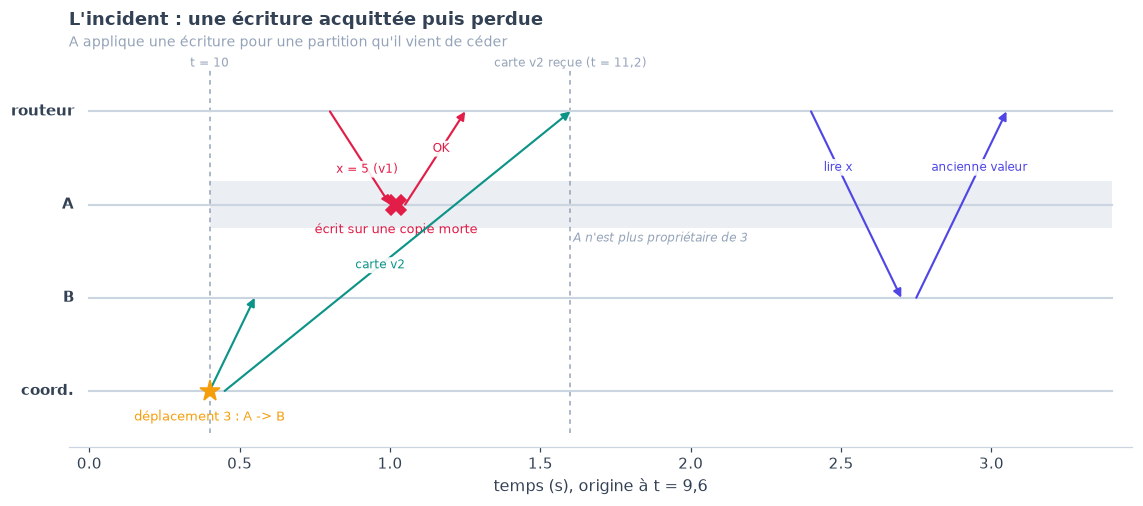

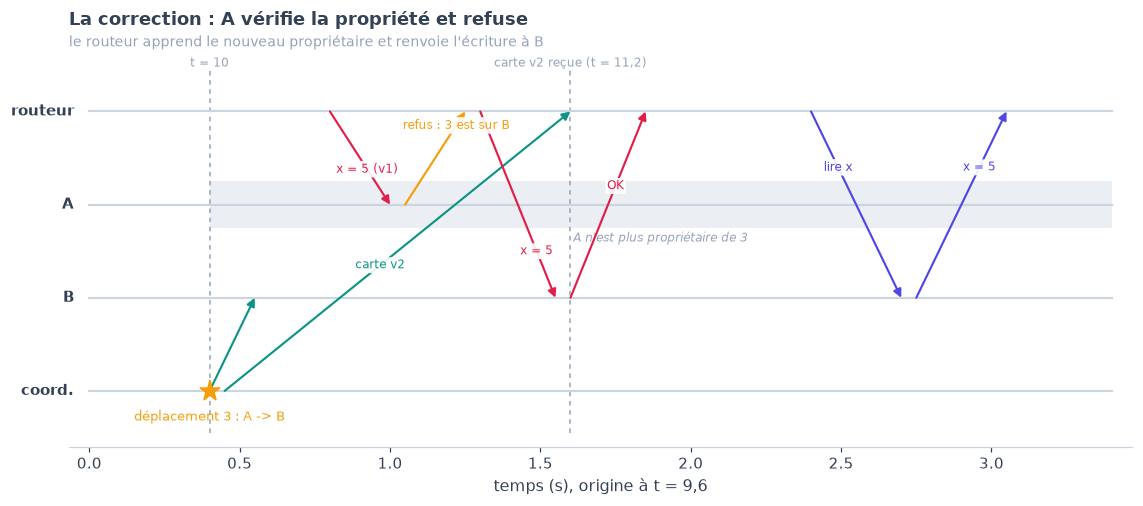

In [2]:
T0 = 9.6   # origine de l'axe : les instants affichés sont t - 9,6
def trace(titre, sous_titre, corrige):
    st = SpaceTime(["routeur", "A", "B", "coord."], t_max=3.4, width=10.5, title=titre, subtitle=sous_titre,
                   time_label="temps (s), origine à t = 9,6")
    st.span("A", 10.0 - T0, 3.4, "A n'est plus propriétaire de 3", color=GRAY, alpha=0.18)
    st.event("coord.", 10.0 - T0, "déplacement 3 : A -> B", kind="star")
    st.msg("coord.", 10.0 - T0, "B", 10.15 - T0, "", color=TEAL)
    st.msg("coord.", 10.05 - T0, "routeur", 11.2 - T0, "carte v2", color=TEAL, label_pos=0.45)
    st.msg("routeur", 10.4 - T0, "A", 10.6 - T0, "x = 5 (v1)", color=ROSE, label_pos=0.62)
    if not corrige:
        st.msg("A", 10.65 - T0, "routeur", 10.85 - T0, "OK", color=ROSE, label_pos=0.6)
        st.event("A", 10.62 - T0, "écrit sur une copie morte", kind="crash")
        st.msg("routeur", 12.0 - T0, "B", 12.3 - T0, "lire x", color=INDIGO, label_pos=0.3)
        st.msg("B", 12.35 - T0, "routeur", 12.65 - T0, "ancienne valeur", color=INDIGO, label_pos=0.7)
    else:
        st.msg("A", 10.65 - T0, "routeur", 10.85 - T0, "refus : 3 est sur B", color=AMBER, label_pos=0.85)
        st.msg("routeur", 10.9 - T0, "B", 11.15 - T0, "x = 5", color=ROSE, label_pos=0.75)
        st.msg("B", 11.2 - T0, "routeur", 11.45 - T0, "OK", color=ROSE, label_pos=0.6)
        st.msg("routeur", 12.0 - T0, "B", 12.3 - T0, "lire x", color=INDIGO, label_pos=0.3)
        st.msg("B", 12.35 - T0, "routeur", 12.65 - T0, "x = 5", color=INDIGO, label_pos=0.7)
    st.vline(10.0 - T0, "t = 10")
    st.vline(11.2 - T0, "carte v2 reçue (t = 11,2)")
    st.show()

trace("L'incident : une écriture acquittée puis perdue",
      "A applique une écriture pour une partition qu'il vient de céder", corrige=False)
trace("La correction : A vérifie la propriété et refuse",
      "le routeur apprend le nouveau propriétaire et renvoie l'écriture à B", corrige=True)

**Vérification.** Un petit modèle : les écritures arrivent selon un processus de Poisson ;
chaque déplacement change le propriétaire à l'instant $t_d$, et le routeur ne l'apprend
qu'à $t_d + \delta$. Sans correction, toute écriture routée vers l'ancien propriétaire
pendant cette fenêtre est perdue ; avec correction, elle est refusée puis renvoyée au
bon nœud (un aller-retour de plus, 1 ms ici).

In [3]:
def simule_routage(duree=1_000.0, debit=200.0, periode=50.0, delai_max=2.0, correction=False, seed=0):
    r = np.random.default_rng(seed)
    t_ecr = np.sort(r.uniform(0, duree, r.poisson(debit * duree)))
    t_dep = np.arange(periode, duree, periode)
    delais = r.uniform(0, delai_max, t_dep.size)
    # pour chaque écriture : y a-t-il un déplacement récent que le routeur ignore encore ?
    k = np.searchsorted(t_dep, t_ecr, side="right") - 1        # dernier déplacement avant l'écriture
    perime = (k >= 0) & (t_ecr < t_dep[np.maximum(k, 0)] + delais[np.maximum(k, 0)])
    latence = np.full(t_ecr.size, 1.0)                           # 1 ms par aller-retour
    if correction:
        latence[perime] += 1.0                                   # refus + nouvel envoi
        perdues = 0
    else:
        perdues = int(perime.sum())
    return {"écritures": t_ecr.size, "attendu sans correction : débit × Σ délais": debit * delais.sum(), "routées vers l'ancien nœud": int(perime.sum()),
            "perdues": perdues, "latence moyenne (ms)": latence.mean(),
            "latence max (ms)": latence.max()}

tab = pd.DataFrame({"sans correction": simule_routage(), "contrôle + époque": simule_routage(correction=True)}).T
attendu = 200 * 1.0 * (1_000 // 50 - 0)          # débit × délai moyen × nombre de déplacements
tab

,écritures,attendu sans correction : débit × Σ délais,routées vers l'ancien nœud,perdues,latence moyenne (ms),latence max (ms)
sans correction,200176.0,2657.983,2627.0,2627.0,1.000,1.0
contrôle + époque,200176.0,2657.983,2627.0,0.0,1.013,2.0


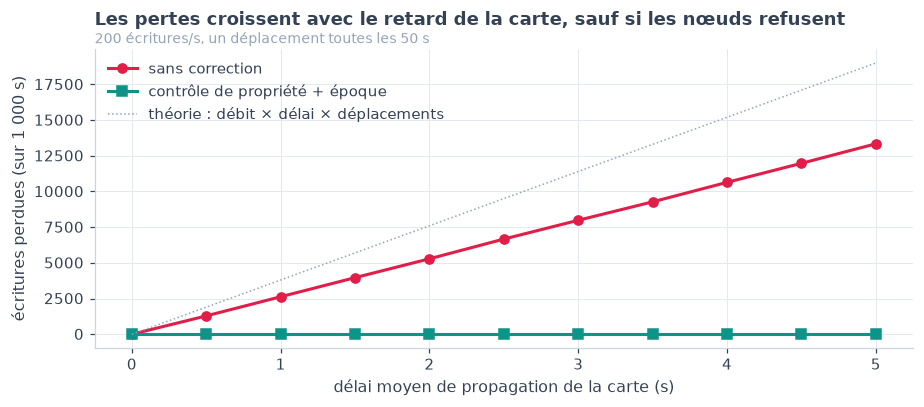

In [4]:
delais = np.linspace(0, 5, 11)
pertes = [simule_routage(delai_max=2 * d)["perdues"] for d in delais]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(delais, pertes, "o-", color=ROSE, label="sans correction")
ax.plot(delais, np.zeros_like(delais), "s-", color=TEAL, label="contrôle de propriété + époque")
ax.plot(delais, 200 * delais * 19, color=GRAY, lw=1, ls=":", label="théorie : débit × délai × déplacements")
ax.set_xlabel("délai moyen de propagation de la carte (s)")
ax.set_ylabel("écritures perdues (sur 1 000 s)")
ax.set_title("Les pertes croissent avec le retard de la carte, sauf si les nœuds refusent")
subtitle(ax, "200 écritures/s, un déplacement toutes les 50 s")
ax.legend()
plt.tight_layout(); plt.show()

Sans correction, on perd plus de 2 600 écritures acquittées en 1 000 s (1,3 % du trafic) :
c'est bien le débit multiplié par la somme des 19 délais tirés (13 s au total, un peu
moins que la moyenne théorique de 19 s), et la perte croît linéairement avec le retard
de la carte. Avec le contrôle de propriété, plus aucune perte : les mêmes requêtes
coûtent un aller-retour de plus, et la latence moyenne n'augmente que de 1,3 %.

> **À retenir.** Dans un système partitionné, les cartes de routage sont toujours un peu
> en retard. La correction ne peut pas venir d'une propagation plus rapide : c'est au
> **nœud de stockage** de vérifier qu'il possède la partition (et la version de la carte)
> avant d'accepter une écriture. Une carte périmée doit coûter un détour, jamais une
> donnée.

## Exercice 6.8 : scatter/gather et latence de queue

**Énoncé.** Une requête sur un index secondaire local est envoyée en parallèle à $n$
partitions ; la réponse attend la plus lente. Chaque partition répond en
5 ms en médiane, mais 1 % de ses réponses sont lentes (pause du ramasse-miettes, disque) :
vingt fois plus longues.

1. Quelle est la probabilité qu'une requête touche au moins une réponse lente, pour
   $n = 10$, 50, 100, 200 ? À partir de quel $n$ la **médiane** de la requête
   elle-même est-elle dégradée ?
2. Simuler les percentiles 50 et 99 de la requête en fonction de $n$.
3. Requêtes de couverture (« hedged requests ») : chaque partition a une réplique ; si une
   réponse n'est pas arrivée au bout du 95e percentile d'une partition, on envoie la même
   requête à la réplique et on garde la première réponse. Quel gain, pour quel surcoût ?

**Rappels.** Interroger toutes les partitions expose à l'amplification de la latence de
queue (cours 4, section *Partitioning Secondary Indexes by Document* ;
chapitre 1, cours 2).

**Solution.**

*1.* Les partitions étant indépendantes, $P(\text{au moins une lente}) = 1 - 0{,}99^n$ :
9,6 % pour $n = 10$, 39 % pour 50, 63 % pour 100, 87 % pour 200. Dès que cette
probabilité dépasse 50 %, c'est-à-dire pour $n \ge 69$ ($\ln 0{,}5 / \ln 0{,}99$), la
**médiane** de la requête est une réponse lente : le cas rare d'une partition est devenu
le cas typique de la requête.

*2.* Voir la simulation : le p99 de la requête se dégrade dès $n = 10$, la médiane
décroche vers $n = 70$.

*3.* Avec la couverture, une réponse lente est remplacée par $d + t_2$, où $d$ est le
p95 d'une partition (environ 14 ms) et $t_2$ le temps de la réplique, presque toujours
rapide. La queue de chaque partition est donc tronquée vers $d + 5$ ms. Le surcoût :
5 % de requêtes en plus (celles qui dépassent le p95), et le travail inutile des
réponses doublées.

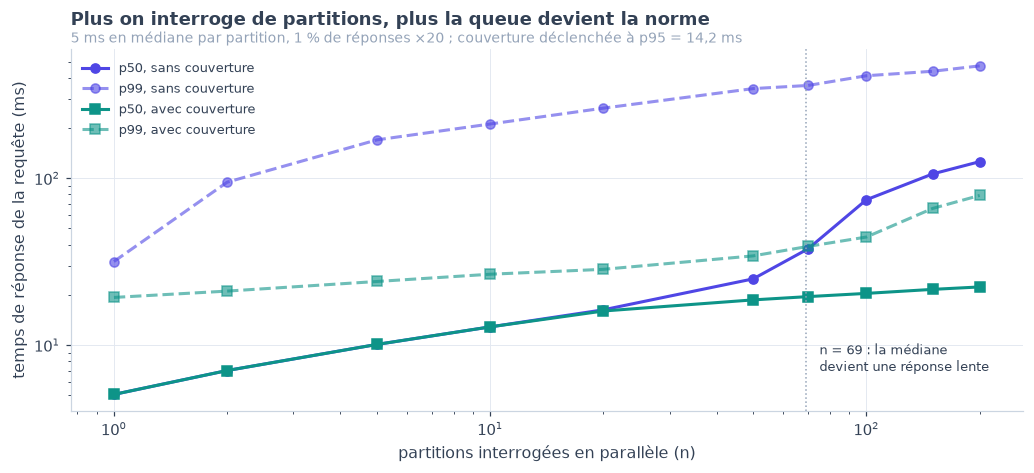

surcoût de la couverture : 5.0% de requêtes supplémentaires


,P(au moins une lente),p50 (ms),p99 (ms),p50 couvert,p99 couvert
n,,,,,
1,0.010,5.067,31.702,5.067,19.313
2,0.020,7.048,94.743,7.048,21.078
5,0.049,10.100,169.797,10.100,24.067
10,0.096,12.866,211.358,12.866,26.605
20,0.182,16.283,263.087,16.017,28.466
50,0.395,24.950,344.482,18.670,34.265
70,0.505,37.790,359.787,19.535,39.054
100,0.634,74.357,411.342,20.422,44.447
150,0.779,106.155,437.532,21.586,65.955


In [5]:
lent = P.lognormal_sampler(median=5.0, sigma=0.6, slow_p=0.01, slow_factor=20.0)
seul = lent(np.random.default_rng(1), 200_000)
d95 = np.percentile(seul, 95)

def couvert(r, size):
    t1, t2 = lent(r, size), lent(r, size)
    return np.where(t1 > d95, np.minimum(t1, d95 + t2), t1)

ns = [1, 2, 5, 10, 20, 50, 70, 100, 150, 200]
rows = []
for n in ns:
    a = P.scatter_gather_latency(n, 20_000, lent, seed=2)
    b = P.scatter_gather_latency(n, 20_000, couvert, seed=2)
    rows.append({"n": n, "P(au moins une lente)": 1 - 0.99 ** n,
                 "p50 (ms)": np.median(a), "p99 (ms)": np.percentile(a, 99),
                 "p50 couvert": np.median(b), "p99 couvert": np.percentile(b, 99)})
tab = pd.DataFrame(rows).set_index("n")

fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.plot(ns, tab["p50 (ms)"], "o-", color=INDIGO, label="p50, sans couverture")
ax.plot(ns, tab["p99 (ms)"], "o--", color=INDIGO, alpha=0.6, label="p99, sans couverture")
ax.plot(ns, tab["p50 couvert"], "s-", color=TEAL, label="p50, avec couverture")
ax.plot(ns, tab["p99 couvert"], "s--", color=TEAL, alpha=0.6, label="p99, avec couverture")
ax.axvline(69, color=GRAY, ls=":", lw=1)
ax.text(75, 7, "n = 69 : la médiane\ndevient une réponse lente", fontsize=8.5, color=SLATE)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("partitions interrogées en parallèle (n)")
ax.set_ylabel("temps de réponse de la requête (ms)")
ax.set_title("Plus on interroge de partitions, plus la queue devient la norme")
subtitle(ax, f"5 ms en médiane par partition, 1 % de réponses ×20 ; couverture déclenchée à p95 = {d95:.1f} ms".replace(".", ","))
ax.legend(fontsize=8.5, loc="upper left")
plt.tight_layout(); plt.show()
print(f"surcoût de la couverture : {np.mean(seul > d95):.1%} de requêtes supplémentaires")
tab.round(3)

La simulation confirme le calcul : le p99 dépasse 200 ms dès 10 partitions, et la
médiane bondit entre 50 et 100 partitions (de 25 ms à plus de 70 ms) quand la moitié des
requêtes rencontrent au moins une réponse lente. Avec la couverture, la médiane reste
autour de 20 ms et le p99 sous 80 ms jusqu'à 200 partitions, pour 5 % de requêtes en plus.
La médiane couverte croît encore doucement avec $n$ : on attend toujours le maximum de
$n$ temps, même tronqués.

> **À retenir.** Une requête qui interroge $n$ partitions vit dans la queue de la
> distribution de chacune : $1 - (1-p)^n$ approche vite 1. Les requêtes de couverture
> coupent cette queue pour quelques pour cent de charge ; mieux encore, une clé de
> partitionnement ou un index global qui évite le scatter/gather.